In [1]:
import torch

text = (
    'python models learn from examples. students inspect errors and improve models. '
) * 30

chars = sorted(
    set(text)
)

to_id = {
    c: i
    for i, c in enumerate(chars)
}

to_char = {
    i: c
    for c, i in to_id.items()
}

encoded = torch.tensor(
    [to_id[c] for c in text],
    dtype=torch.long
)

print(
    len(text),
    len(chars),
    chars
)

2370 21 [' ', '.', 'a', 'c', 'd', 'e', 'f', 'h', 'i', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'x', 'y']


## Text and Vocabulary

Characters must be converted into integer IDs before they can be used by a neural network.

The vocabulary contains every unique character that appears in the text.

Any character missing from the vocabulary could not be represented by the model.

In [3]:
n = len(encoded)

train_ids = encoded[:int(.7 * n)]

val_ids = encoded[
    int(.7 * n):
    int(.85 * n)
]

test_ids = encoded[
    int(.85 * n):
]

window = 20

def pairs(ids):

    X = torch.stack(
        [
            ids[i:i + window]
            for i in range(
                len(ids) - window
            )
        ]
    )

    y = ids[window:]

    return X, y

X_train, y_train = pairs(
    train_ids
)

X_val, y_val = pairs(
    val_ids
)

X_test, y_test = pairs(
    test_ids
)

print(
    X_train.shape,
    X_val.shape,
    X_test.shape
)

torch.Size([1639, 20]) torch.Size([335, 20]) torch.Size([336, 20])


## Train Validation Test Split

Each input contains 20 characters.

The model attempts to predict the next character after the 20-character window.

The final test portion remains untouched until the final evaluation.

In [4]:
import torch.nn as nn

class CharGRU(nn.Module):

    def __init__(self,
                 vocab_size,
                 embed_dim=16,
                 hidden_size=32):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.gru = nn.GRU(
            embed_dim,
            hidden_size,
            batch_first=True
        )

        self.output = nn.Linear(
            hidden_size,
            vocab_size
        )

    def forward(self, x):

        x = self.embedding(x)

        _, hidden = self.gru(x)

        return self.output(
            hidden.squeeze(0)
        )

model = CharGRU(
    len(chars)
)

print(model)

CharGRU(
  (embedding): Embedding(21, 16)
  (gru): GRU(16, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=21, bias=True)
)


## GRU Model

The embedding layer converts character IDs into dense numeric vectors.

The GRU reads the character sequence one step at a time.

The final linear layer produces one score for every character in the vocabulary.

The character with the highest score becomes the predicted next character.

In [5]:
from torch.utils.data import (
    TensorDataset,
    DataLoader
)

train_loader = DataLoader(
    TensorDataset(
        X_train,
        y_train
    ),
    batch_size=64,
    shuffle=True
)

print(
    "Training batches:",
    len(train_loader)
)

Training batches: 26


In [7]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

print(loss_function)

CrossEntropyLoss()


In [8]:
train_losses = []
val_losses = []

for epoch in range(10):

    model.train()

    running_loss = 0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        logits = model(xb)

        loss = loss_function(
            logits,
            yb
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = (
        running_loss /
        len(train_loader)
    )

    train_losses.append(
        train_loss
    )

    model.eval()

    with torch.inference_mode():

        logits = model(
            X_val
        )

        val_loss = (
            loss_function(
                logits,
                y_val
            ).item()
        )

    val_losses.append(
        val_loss
    )

    print(
        f"Epoch {epoch + 1}",
        round(train_loss, 4),
        round(val_loss, 4)
    )


Epoch 1 2.334 1.5477
Epoch 2 0.982 0.4688
Epoch 3 0.2753 0.1395
Epoch 4 0.103 0.0693
Epoch 5 0.0584 0.0524
Epoch 6 0.0462 0.0382
Epoch 7 0.0384 0.0338
Epoch 8 0.0332 0.0287
Epoch 9 0.0304 0.0263
Epoch 10 0.0273 0.0254


In [9]:
from sklearn.metrics import accuracy_score

model.eval()

with torch.inference_mode():

    logits = model(X_val)

    predictions = logits.argmax(dim=1)

validation_accuracy = accuracy_score(
    y_val.numpy(),
    predictions.numpy()
)

print(
    "Validation Accuracy:",
    round(
        validation_accuracy,
        4
    )
)

Validation Accuracy: 0.9881


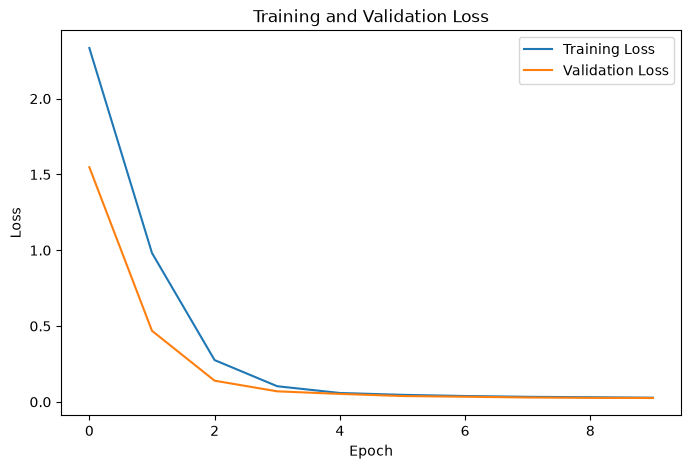

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.show()


## Training and Validation Performance

Both training loss and validation loss decreased steadily during training.

The validation loss continued decreasing throughout training and did not show signs of instability.

The pattern suggests continued learning and does not provide strong evidence of overfitting.

The close relationship between training and validation loss indicates that the model generalizes well to unseen validation examples.

In [24]:
model.eval()

with torch.inference_mode():

    logits = model(X_test)

    predictions = logits.argmax(dim=1)

test_accuracy = (
    (predictions == y_test)
    .float()
    .mean()
    .item()
)

print(
    "Test Accuracy:",
    round(
        test_accuracy,
        4
    )
)

Test Accuracy: 0.9881


In [25]:
seed = "python models learn "

context = torch.tensor(
    [
        [
            to_id[c]
            for c in seed[-window:]
        ]
    ],
    dtype=torch.long
)

model.eval()

with torch.inference_mode():

    logits = model(context)

next_character = to_char[
    logits.argmax(dim=1).item()
]

print(
    "Seed:",
    seed
)

print(
    "Predicted Next Character:",
    next_character
)

Seed: python models learn 
Predicted Next Character: f


## Controlled Experiment Prediction

I predict that reducing the GRU hidden size from 32 to 16 will slightly reduce accuracy because the model will have fewer parameters available to learn character relationships.

The smaller model may train faster but may not capture as much information from the training sequences.